# Phase 4: Exploratory Data Analysis and Data Cleaning

**Member:** Member 2  
**Input:** `data/interim/integrated_cars_raw.csv`  
**Output:** `data/processed/cleaned_cars.csv`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/interim/integrated_cars_raw.csv")

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (295454, 5)


C:\Users\Omar Essam\AppData\Local\Temp\ipykernel_33920\3529366937.py:8: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/interim/integrated_cars_raw.csv")


,make,model,year,price,data_source
0,ford,explorer st,2022.0,27999,kaggle
1,volkswagen,bug,1969.0,2200,kaggle
2,rover,sport,2016.0,15999,kaggle
3,cadillac,eldorado convertible,1974.0,12000,kaggle
4,dodge,challenger lc srt8,2009.0,18999,kaggle


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295454 entries, 0 to 295453
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   make         284662 non-null  object 
 1   model        292095 non-null  object 
 2   year         295428 non-null  float64
 3   price        295454 non-null  object 
 4   data_source  295454 non-null  object 
dtypes: float64(1), object(4)
memory usage: 11.3+ MB


## 1. Data Quality Assessment

Checking missing values, duplicate rows, data types, and the raw format of price values.

In [2]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum())

# Missing values percentage
print("\nMissing values percentage:")
display((df.isnull().sum() / len(df) * 100).round(2))

# Duplicate rows
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Unique values in each column
print("\nUnique values per column:")
display(df.nunique())

# Inspect raw values inside the price column
print("\nSample raw price values:")
display(df["price"].dropna().sample(20, random_state=42))

Missing values per column:


make           10792
model           3359
year              26
price              0
data_source        0
dtype: int64


Missing values percentage:


make           3.65
model          1.14
year           0.01
price          0.00
data_source    0.00
dtype: float64


Duplicate rows: 101895

Unique values per column:


make              42
model          27958
year             114
price          20717
data_source        2
dtype: int64


Sample raw price values:


254660    22995
116476        0
227754    26949
154415    23900
107145     6995
271662     2000
73348      1295
18504     33700
42583         1
116366        0
153933    19995
188548    75900
197023     5995
253131     2700
151577        1
273702     5395
39124     20995
220419     9479
70403      7500
91120     39997
Name: price, dtype: object

## 2. Duplicate and Price Investigation

Investigating duplicate records and identifying invalid or non-numeric price values before applying cleaning rules.

In [3]:
# Duplicate analysis
print("Exact duplicate rows:", df.duplicated().sum())

print("\nDuplicate rows by data source:")
display(
    df[df.duplicated(keep=False)]
    .groupby("data_source")
    .size()
    .rename("duplicate_rows")
)

# Check whether duplicate values differ only by data source
duplicates_without_source = df.duplicated(
    subset=["make", "model", "year", "price"],
    keep=False
).sum()

print(f"\nRows duplicated based on make, model, year, and price: {duplicates_without_source}")

# Price type analysis
print("\nPython types found in price:")
display(df["price"].map(type).value_counts())

# Convert price temporarily, without changing df yet
price_numeric_check = pd.to_numeric(df["price"], errors="coerce")

print("\nPrice values that cannot be converted to numbers:")
display(df.loc[price_numeric_check.isna(), "price"].drop_duplicates().head(30))

print(f"\nNon-numeric price values count: {price_numeric_check.isna().sum()}")
print(f"Prices less than or equal to zero: {(price_numeric_check <= 0).sum()}")
print(f"Prices equal to 1: {(price_numeric_check == 1).sum()}")

Exact duplicate rows: 101895

Duplicate rows by data source:


data_source
kaggle    147062
Name: duplicate_rows, dtype: int64


Rows duplicated based on make, model, year, and price: 147062

Python types found in price:


price
<class 'int'>    164382
<class 'str'>    131072
Name: count, dtype: int64


Price values that cannot be converted to numbers:


Series([], Name: price, dtype: object)


Non-numeric price values count: 0
Prices less than or equal to zero: 10288
Prices equal to 1: 637


## 3. Initial Cleaning and Numeric Validation

Creating a clean working copy, removing exact duplicates, converting price to numeric, and inspecting invalid price and year values.

In [4]:
# Create a separate working copy
df_clean = df.copy()

# Remove only fully identical duplicate rows
rows_before_duplicates = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()

print(f"Rows before removing exact duplicates: {rows_before_duplicates:,}")
print(f"Rows after removing exact duplicates:  {len(df_clean):,}")
print(f"Removed duplicate rows:               {rows_before_duplicates - len(df_clean):,}")

# Make price numeric
df_clean["price"] = pd.to_numeric(df_clean["price"], errors="coerce")

# Check suspicious price values
print("\nPrice values less than or equal to 1:")
display(df_clean.loc[df_clean["price"] <= 1, ["make", "model", "year", "price", "data_source"]].head(20))

print("\nCount for each price value <= 1:")
display(df_clean.loc[df_clean["price"] <= 1, "price"].value_counts().sort_index())

# Year validation
print("\nYear range:")
print("Minimum year:", df_clean["year"].min())
print("Maximum year:", df_clean["year"].max())

print("\nRows with missing or suspicious years:")
display(
    df_clean.loc[
        df_clean["year"].isna() | (df_clean["year"] < 1886) | (df_clean["year"] > 2026),
        ["make", "model", "year", "price", "data_source"]
    ].head(30)
)

Rows before removing exact duplicates: 295,454
Rows after removing exact duplicates:  193,559
Removed duplicate rows:               101,895

Price values less than or equal to 1:


,make,model,year,price,data_source
49,ford,f-150 xlt,2026.0,0.0,kaggle
83,ford,bronco sport big bend,2026.0,0.0,kaggle
101,mercedes-benz,gle350,2023.0,0.0,kaggle
327,honda,accord lx sedan 4d,2011.0,0.0,kaggle
332,lexus,nx,2020.0,0.0,kaggle
333,mazda,cx 30,2025.0,0.0,kaggle
338,mini,hardtop 4 door cooper hatc,2015.0,0.0,kaggle
370,lexus,rc,2016.0,0.0,kaggle
371,lexus,gs,2015.0,0.0,kaggle
372,lexus,rx,2023.0,0.0,kaggle



Count for each price value <= 1:


price
0.0    5111
1.0     452
Name: count, dtype: int64


Year range:
Minimum year: 1900.0
Maximum year: 2027.0

Rows with missing or suspicious years:


,make,model,year,price,data_source
456,ford,expedition max platinum,2027.0,1658.0,kaggle
577,toyota,corolla le,2027.0,0.0,kaggle
606,toyota,camry se,2027.0,0.0,kaggle
857,ford,super duty f-350 srw xl,2027.0,1092.0,kaggle
895,ford,super duty f-350 srw xl,2027.0,1091.0,kaggle
934,toyota,camry hybrid le,2027.0,29999.0,kaggle
2384,ford,super duty f-250 srw xl,2027.0,974.0,kaggle
2848,ford,super duty f-350 lariat,2027.0,1816.0,kaggle
2938,ford,transit van,2027.0,1193.0,kaggle
3348,toyota,corolla hybrid le,2027.0,0.0,kaggle


## 4. Core Cleaning Rules

- Remove exact duplicate records.
- Remove records with invalid target prices (`price` <= 1).
- Remove records with missing year values.
- Standardize text fields and mark missing make/model values as `unknown`.

In [5]:
# 1) Remove rows with invalid target prices
rows_before_price_cleaning = len(df_clean)
df_clean = df_clean[df_clean["price"] > 1].copy()

print(f"Removed rows with price <= 1: {rows_before_price_cleaning - len(df_clean):,}")

# 2) Remove rows with missing year
rows_before_year_cleaning = len(df_clean)
df_clean = df_clean.dropna(subset=["year"]).copy()

print(f"Removed rows with missing year: {rows_before_year_cleaning - len(df_clean):,}")

# Convert valid years to integers
df_clean["year"] = df_clean["year"].astype(int)

# 3) Standardize text columns
for column in ["make", "model"]:
    df_clean[column] = (
        df_clean[column]
        .fillna("unknown")
        .astype(str)
        .str.strip()
        .str.lower()
        .replace("", "unknown")
    )

# Final validation after core cleaning
print("\nCleaned dataset shape:", df_clean.shape)

print("\nMissing values after core cleaning:")
display(df_clean.isnull().sum())

print("\nInvalid prices remaining (<= 1):", (df_clean["price"] <= 1).sum())
print("Duplicate rows remaining:", df_clean.duplicated().sum())

print("\nMissing-category counts:")
print("make = unknown:", (df_clean["make"] == "unknown").sum())
print("model = unknown:", (df_clean["model"] == "unknown").sum())

Removed rows with price <= 1: 5,563
Removed rows with missing year: 8

Cleaned dataset shape: (187988, 5)

Missing values after core cleaning:


make           0
model          0
year           0
price          0
data_source    0
dtype: int64


Invalid prices remaining (<= 1): 0
Duplicate rows remaining: 14618

Missing-category counts:
make = unknown: 7714
model = unknown: 2231


## 5. Final Duplicate Removal

Removing duplicates that became identical after standardizing make and model values.

In [6]:
# Remove duplicates created after text standardization
rows_before_final_deduplication = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

final_duplicates_removed = rows_before_final_deduplication - len(df_clean)

print(f"Duplicates removed after text standardization: {final_duplicates_removed:,}")
print(f"Final cleaned dataset shape: {df_clean.shape}")
print(f"Remaining duplicate rows: {df_clean.duplicated().sum()}")

print("\nFinal rows by data source:")
display(df_clean["data_source"].value_counts())

print("\nFinal data types:")
display(df_clean.dtypes)

Duplicates removed after text standardization: 14,618
Final cleaned dataset shape: (173370, 5)
Remaining duplicate rows: 0

Final rows by data source:


data_source
kaggle         173367
web_scraped         3
Name: count, dtype: int64


Final data types:


make            object
model           object
year             int64
price          float64
data_source     object
dtype: object

## Final Data Validation

Validating that the cleaned dataset has no missing values, duplicates, invalid prices, empty text values, or invalid years.

In [7]:
# Final validation checks
validation_results = {
    "missing_values": int(df_clean.isna().sum().sum()),
    "duplicate_rows": int(df_clean.duplicated().sum()),
    "prices_less_than_or_equal_to_1": int((df_clean["price"] <= 1).sum()),
    "empty_make_values": int((df_clean["make"].str.strip() == "").sum()),
    "empty_model_values": int((df_clean["model"].str.strip() == "").sum()),
    "years_before_1886": int((df_clean["year"] < 1886).sum()),
    "years_after_2030": int((df_clean["year"] > 2030).sum()),
    "invalid_data_source_values": int(
        (~df_clean["data_source"].isin(["kaggle", "web_scraped"])).sum()
    ),
}

validation_report = pd.DataFrame.from_dict(
    validation_results,
    orient="index",
    columns=["invalid_count"]
)

validation_report["status"] = np.where(
    validation_report["invalid_count"] == 0,
    "PASS",
    "CHECK"
)

display(validation_report)

print("\nDataset shape:", df_clean.shape)
print("Year range:", df_clean["year"].min(), "to", df_clean["year"].max())
print("Price range:", df_clean["price"].min(), "to", df_clean["price"].max())

print("\nData source counts:")
display(df_clean["data_source"].value_counts())

print("\nRows with unknown categories (allowed, but documented):")
print("Unknown make:", (df_clean["make"] == "unknown").sum())
print("Unknown model:", (df_clean["model"] == "unknown").sum())

,invalid_count,status
missing_values,0,PASS
duplicate_rows,0,PASS
prices_less_than_or_equal_to_1,0,PASS
empty_make_values,0,PASS
empty_model_values,0,PASS
years_before_1886,0,PASS
years_after_2030,0,PASS
invalid_data_source_values,0,PASS



Dataset shape: (173370, 5)
Year range: 1900 to 2027
Price range: 2.0 to 1e+24

Data source counts:


data_source
kaggle         173367
web_scraped         3
Name: count, dtype: int64


Rows with unknown categories (allowed, but documented):
Unknown make: 7319
Unknown model: 2112


## Save Cleaned Dataset

**Input dataset:** `data/interim/integrated_cars_raw.csv`  
**Output dataset:** `data/processed/cleaned_cars.csv`

Cleaning steps applied:

- Removed exact duplicate records, including duplicates revealed after standardizing text values.
- Converted `price` to numeric.
- Removed rows with missing `year`.
- Replaced missing `make` and `model` values with `unknown`.
- Removed invalid target prices outside the accepted range:
  - Below `$500`
  - Above `$500,000`

Final validation passed:

- No missing values
- No duplicate rows
- All prices are within `$500` to `$500,000`
- Valid year values only

**Final dataset shape:** `(171,923, 5)`

In [8]:
output_path = "../data/processed/cleaned_cars.csv"

df_clean.to_csv(output_path, index=False)

print(f"Cleaned dataset saved successfully to: {output_path}")

# Verification: read the saved file and confirm its shape
saved_df = pd.read_csv(output_path)

print("Saved dataset shape:", saved_df.shape)
display(saved_df.head())

Cleaned dataset saved successfully to: ../data/processed/cleaned_cars.csv
Saved dataset shape: (173370, 5)


,make,model,year,price,data_source
0,ford,explorer st,2022,27999.0,kaggle
1,volkswagen,bug,1969,2200.0,kaggle
2,rover,sport,2016,15999.0,kaggle
3,cadillac,eldorado convertible,1974,12000.0,kaggle
4,dodge,challenger lc srt8,2009,18999.0,kaggle


## 6. Price Distribution and Outlier Analysis

Exploring the target variable (`price`) using descriptive statistics, histograms, and boxplots.

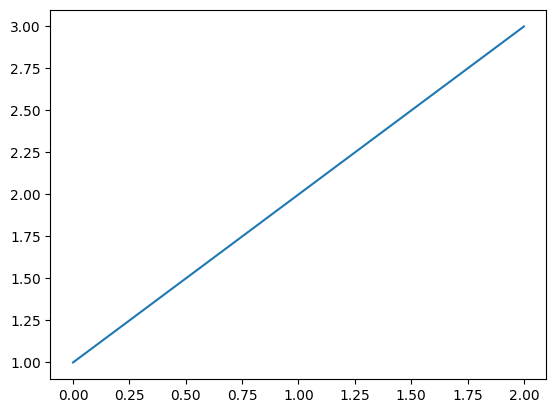

In [1]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3])
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_clean = pd.read_csv("../data/processed/cleaned_cars.csv")

print(df_clean.shape)
display(df_clean.head())

(173370, 5)


,make,model,year,price,data_source
0,ford,explorer st,2022,27999.0,kaggle
1,volkswagen,bug,1969,2200.0,kaggle
2,rover,sport,2016,15999.0,kaggle
3,cadillac,eldorado convertible,1974,12000.0,kaggle
4,dodge,challenger lc srt8,2009,18999.0,kaggle


count    1.733700e+05
mean     5.768011e+18
std      2.401668e+21
min      2.000000e+00
25%      6.000000e+03
50%      1.150000e+04
75%      1.999800e+04
max      1.000000e+24
Name: price, dtype: float64

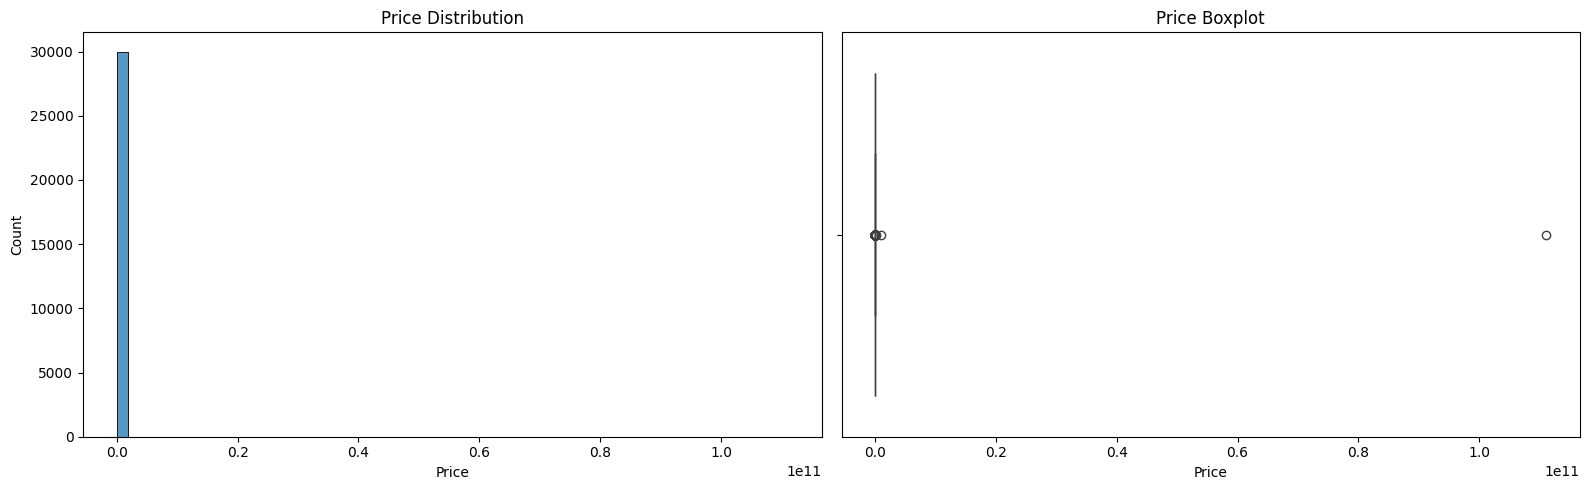

In [3]:
# Price summary
display(df_clean["price"].describe())

# Use a sample for faster plotting
plot_prices = df_clean["price"].sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(plot_prices, bins=60, kde=False, ax=axes[0])
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price")

sns.boxplot(x=plot_prices, ax=axes[1])
axes[1].set_title("Price Boxplot")
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

In [4]:
# Inspect extremely high and likely invalid prices
high_price_threshold = 500_000

suspicious_high_prices = df_clean[df_clean["price"] > high_price_threshold].copy()

print("Number of prices above $500,000:", len(suspicious_high_prices))
print(
    "Percentage of dataset:",
    round(len(suspicious_high_prices) / len(df_clean) * 100, 4),
    "%"
)

display(
    suspicious_high_prices
    .sort_values("price", ascending=False)
    [["make", "model", "year", "price", "data_source"]]
    .head(30)
)

print("\nHighest 20 distinct price values:")
display(df_clean["price"].sort_values(ascending=False).head(20))

Number of prices above $500,000: 48
Percentage of dataset: 0.0277 %


,make,model,year,price,data_source
79586,mazda,protege,2001,1.000000e+24,kaggle
36443,ford,f-150,1991,1.111111e+16,kaggle
68090,gmc,unknown,1950,1.000000e+12,kaggle
108559,chevrolet,unknown,2017,1.111111e+11,kaggle
79532,unknown,any,2017,1.111111e+10,kaggle
25090,chevrolet,unknown,1967,1.111111e+09,kaggle
24741,ram,2500hd,2007,1.000000e+09,kaggle
39440,chevrolet,silverado 2500,2016,9.876543e+08,kaggle
39438,chevrolet,silverado,2012,9.876543e+08,kaggle
171316,ram,3500,2002,9.876543e+08,kaggle



Highest 20 distinct price values:


79586     1.000000e+24
36443     1.111111e+16
68090     1.000000e+12
108559    1.111111e+11
79532     1.111111e+10
25090     1.111111e+09
24741     1.000000e+09
39440     9.876543e+08
171316    9.876543e+08
39438     9.876543e+08
159673    1.234568e+08
88233     1.234568e+08
36960     1.234568e+08
36634     1.234568e+08
13476     1.234568e+08
88234     1.234568e+08
36627     1.234568e+08
36855     1.234565e+08
88326     1.111111e+08
10372     1.000000e+08
Name: price, dtype: float64

In [5]:
df_clean = df_clean[df_clean["price"] <= 500_000].copy()

print("Dataset shape:", df_clean.shape)
print("Maximum remaining price:", df_clean["price"].max())

Dataset shape: (173322, 5)
Maximum remaining price: 500000.0


In [6]:
df_clean.to_csv("../data/processed/cleaned_cars.csv", index=False)

print("Updated cleaned file saved successfully.")

Updated cleaned file saved successfully.


count    173322.000000
mean      16058.413404
std       17670.477546
min           2.000000
25%        6000.000000
50%       11500.000000
75%       19997.000000
max      500000.000000
Name: price, dtype: float64

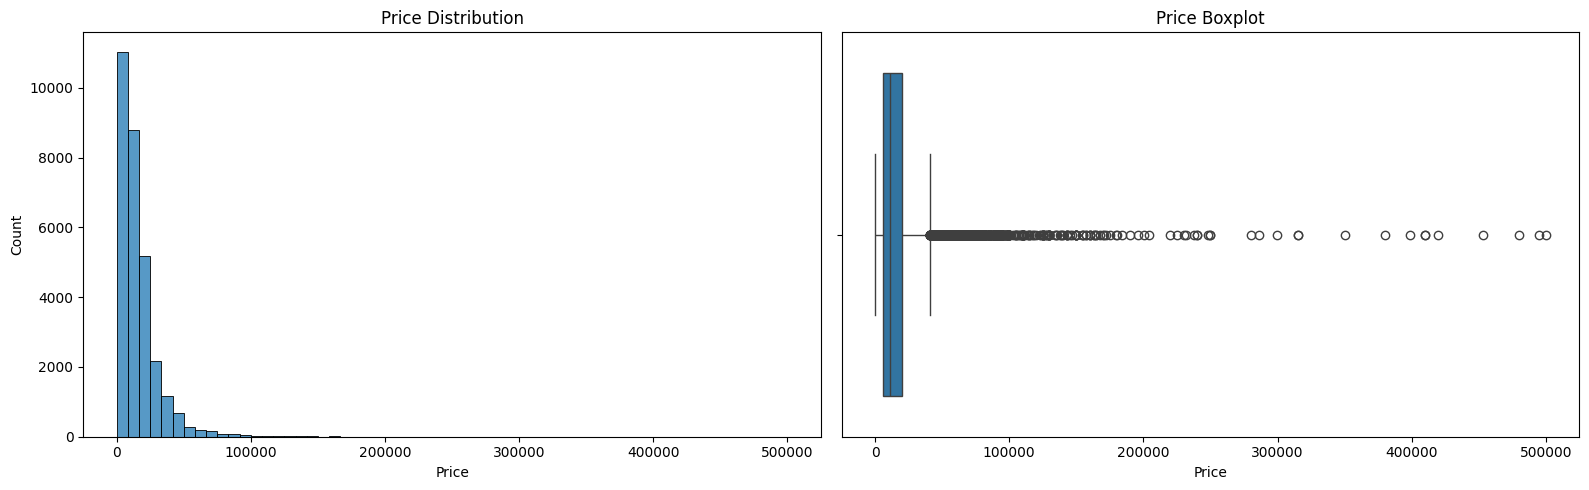

In [7]:
display(df_clean["price"].describe())

plot_prices = df_clean["price"].sample(30000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(plot_prices, bins=60, kde=False, ax=axes[0])
axes[0].set_title("Price Distribution")
axes[0].set_xlabel("Price")

sns.boxplot(x=plot_prices, ax=axes[1])
axes[1].set_title("Price Boxplot")
axes[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

In [8]:
low_price_threshold = 500

suspicious_low_prices = df_clean[df_clean["price"] < low_price_threshold].copy()

print("Number of prices below $500:", len(suspicious_low_prices))
print(
    "Percentage of dataset:",
    round(len(suspicious_low_prices) / len(df_clean) * 100, 4),
    "%"
)

display(
    suspicious_low_prices
    .sort_values("price")
    [["make", "model", "year", "price", "data_source"]]
    .head(30)
)

Number of prices below $500: 1399
Percentage of dataset: 0.8072 %


,make,model,year,price,data_source
3700,dodge,m37,1952,2.0,kaggle
50390,unknown,avalanche,2003,2.0,kaggle
6743,ford,f-150 lightning flash,2024,2.0,kaggle
23486,toyota,sienna,2002,2.0,kaggle
106995,toyota,corolla,2013,2.0,kaggle
121476,dodge,dart gt,1963,2.0,kaggle
104788,chevrolet,malibu lt,2012,2.0,kaggle
7065,gmc,terrain slt,2024,2.0,kaggle
89902,chevrolet,suburban 1500,2008,3.0,kaggle
109354,chrysler,labaron,1994,3.0,kaggle


In [9]:
df_clean = df_clean[
    df_clean["price"].between(500, 500_000)
].copy()

print("Final dataset shape:", df_clean.shape)
print("Minimum remaining price:", df_clean["price"].min())
print("Maximum remaining price:", df_clean["price"].max())

# Update the saved cleaned file
df_clean.to_csv("../data/processed/cleaned_cars.csv", index=False)

print("Final cleaned_cars.csv saved successfully.")

Final dataset shape: (171923, 5)
Minimum remaining price: 500.0
Maximum remaining price: 500000.0
Final cleaned_cars.csv saved successfully.


In [10]:
final_checks = {
    "missing_values": df_clean.isna().sum().sum(),
    "duplicate_rows": df_clean.duplicated().sum(),
    "prices_below_500": (df_clean["price"] < 500).sum(),
    "prices_above_500000": (df_clean["price"] > 500_000).sum(),
    "invalid_years": (
        (df_clean["year"] < 1886) | (df_clean["year"] > 2030)
    ).sum(),
}

validation_report = pd.DataFrame.from_dict(
    final_checks,
    orient="index",
    columns=["invalid_count"]
)

validation_report["status"] = validation_report["invalid_count"].apply(
    lambda count: "PASS" if count == 0 else "CHECK"
)

display(validation_report)
print("\nFinal dataset shape:", df_clean.shape)

,invalid_count,status
missing_values,0,PASS
duplicate_rows,0,PASS
prices_below_500,0,PASS
prices_above_500000,0,PASS
invalid_years,0,PASS



Final dataset shape: (171923, 5)


## 7. Exploratory Data Analysis

### Vehicle Years and Most Common Makes

Year summary:


count    171923.000000
mean       2011.793029
std          12.261487
min        1900.000000
25%        2008.000000
50%        2015.000000
75%        2019.000000
max        2027.000000
Name: year, dtype: float64

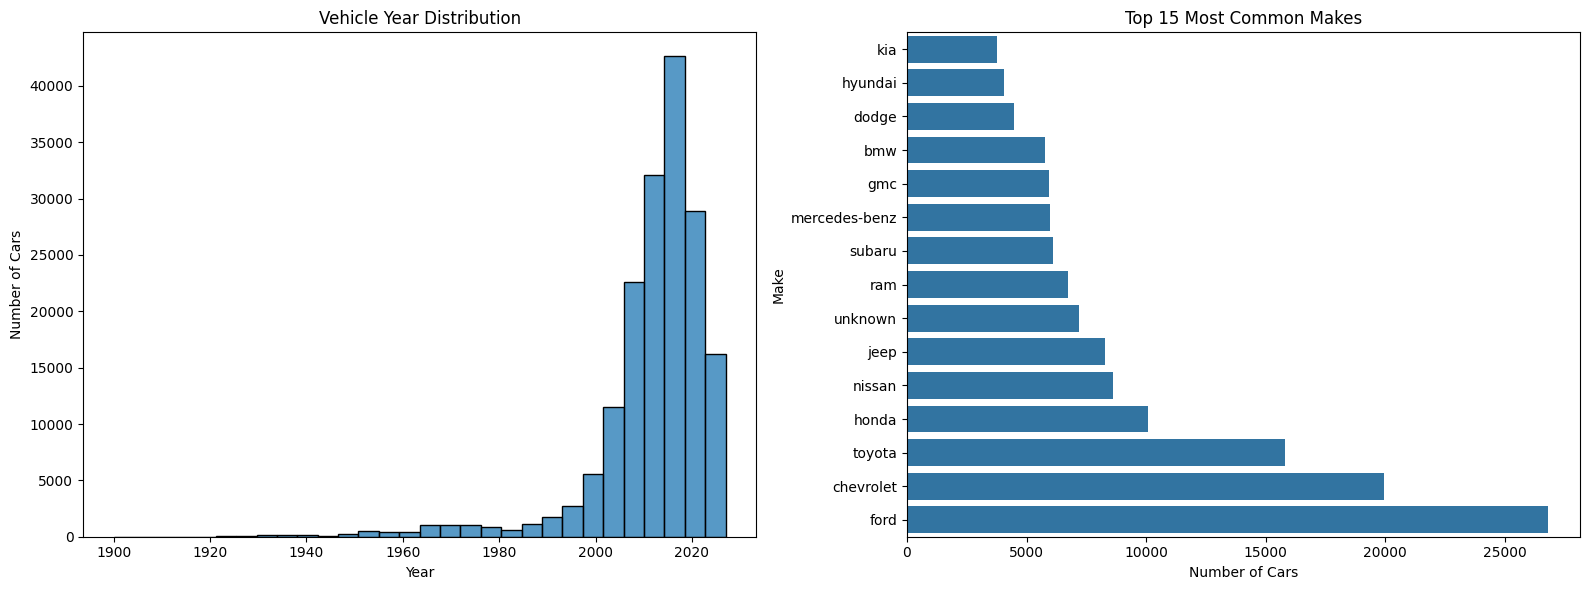

In [11]:
print("Year summary:")
display(df_clean["year"].describe())

top_makes = df_clean["make"].value_counts().head(15).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(df_clean["year"], bins=30, ax=axes[0])
axes[0].set_title("Vehicle Year Distribution")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Cars")

sns.barplot(
    x=top_makes.values,
    y=top_makes.index,
    ax=axes[1]
)
axes[1].set_title("Top 15 Most Common Makes")
axes[1].set_xlabel("Number of Cars")
axes[1].set_ylabel("Make")

plt.tight_layout()
plt.show()

### Relationship Between Vehicle Year and Price

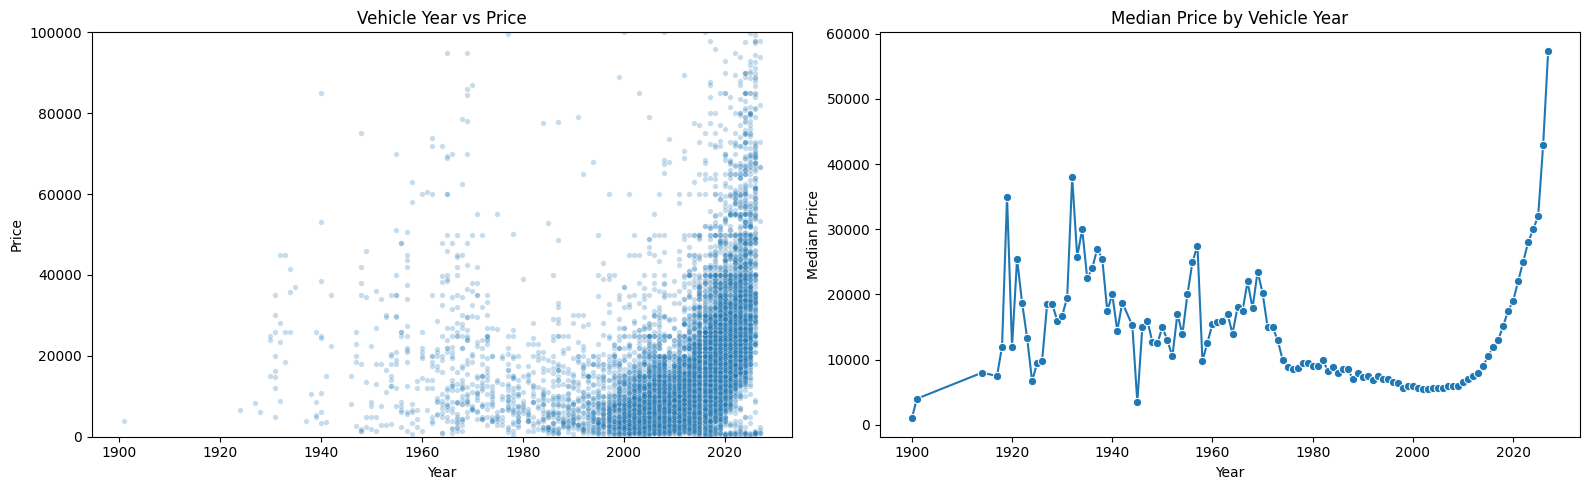

In [12]:
# Sample for a clear scatter plot
year_price_sample = df_clean.sample(15000, random_state=42)

# Median price for every model year
median_price_by_year = (
    df_clean.groupby("year", as_index=False)["price"]
    .median()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.scatterplot(
    data=year_price_sample,
    x="year",
    y="price",
    alpha=0.25,
    s=15,
    ax=axes[0]
)
axes[0].set_title("Vehicle Year vs Price")
axes[0].set_ylim(0, 100000)
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Price")

sns.lineplot(
    data=median_price_by_year,
    x="year",
    y="price",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Median Price by Vehicle Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Median Price")

plt.tight_layout()
plt.show()

### Price Comparison Across Common Makes

,make,car_count,median_price,mean_price
6,nissan,8600,8000.0,10292.110465
3,honda,10092,10500.0,12504.087792
8,subaru,6105,11500.0,12947.317936
4,jeep,8278,12000.0,14216.944793
0,chevrolet,19936,12500.0,17024.464486
5,mercedes-benz,5977,12800.0,19478.117618
1,ford,26811,12888.0,17464.684495
9,toyota,15830,13500.0,16531.993493
2,gmc,5933,15000.0,20876.527221
7,ram,6753,19889.0,23200.323116


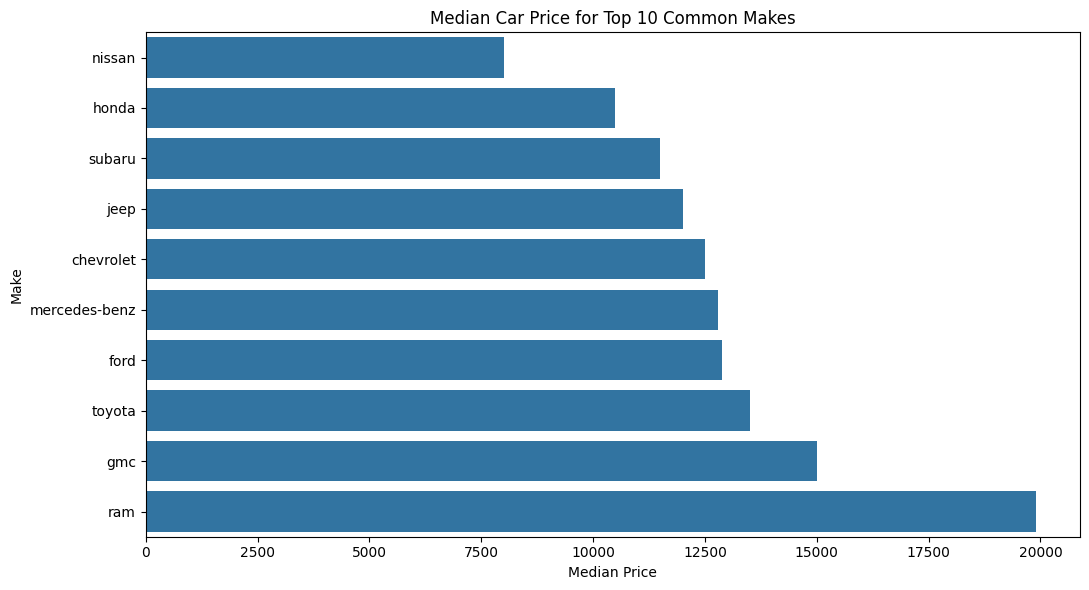

In [13]:
# Select the 10 most common known makes
top_10_known_makes = (
    df_clean[df_clean["make"] != "unknown"]["make"]
    .value_counts()
    .head(10)
    .index
)

make_price_summary = (
    df_clean[df_clean["make"].isin(top_10_known_makes)]
    .groupby("make", as_index=False)
    .agg(
        car_count=("price", "size"),
        median_price=("price", "median"),
        mean_price=("price", "mean")
    )
    .sort_values("median_price")
)

display(make_price_summary)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=make_price_summary,
    x="median_price",
    y="make"
)

plt.title("Median Car Price for Top 10 Common Makes")
plt.xlabel("Median Price")
plt.ylabel("Make")
plt.tight_layout()
plt.show()

## EDA Findings

- The final cleaned dataset contains 171,923 records and 5 columns.
- Price is right-skewed: the median price is lower than the mean price.
- Most vehicles were manufactured between 2008 and 2019, with a median model year of 2015.
- Newer vehicles generally have higher prices, although the relationship varies by vehicle type and make.
- Ford, Chevrolet, and Toyota are the most frequent known makes in the dataset.
- Median prices differ across makes; Ram and GMC have higher median prices among the most common makes, while Nissan has the lowest.
- `make`, `model`, and `year` are relevant features for price prediction.